In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

In [3]:
url = 'amz_uk_price_prediction.csv'
amz = pd.read_csv(url)

In [4]:
amz

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [5]:
#frequency table
cat_frequency = amz['category'].value_counts().reset_index()
cat_frequency
#top 5 most listed categories are Sports & Outdoors, Beauty, Handmade Clothing, Bath & Body, Birthday Gifts

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Alexa Built-In Devices,107
292,Motorbike Chassis,107
293,Plugs,107
294,Smart Home Security & Lighting,104


In [6]:
# selecting subset of category
cat_subset = cat_frequency[cat_frequency['count']>18000]

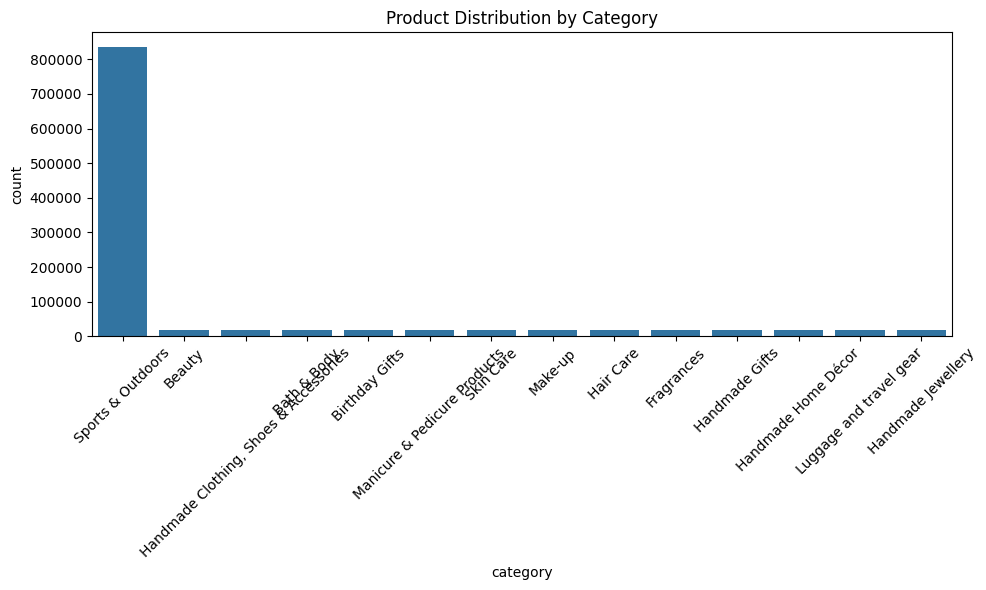

In [7]:
#Visualizations

plt.figure(figsize=(10, 6))
sns.barplot(data=cat_subset, x='category', y='count')

plt.title('Product Distribution by Category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

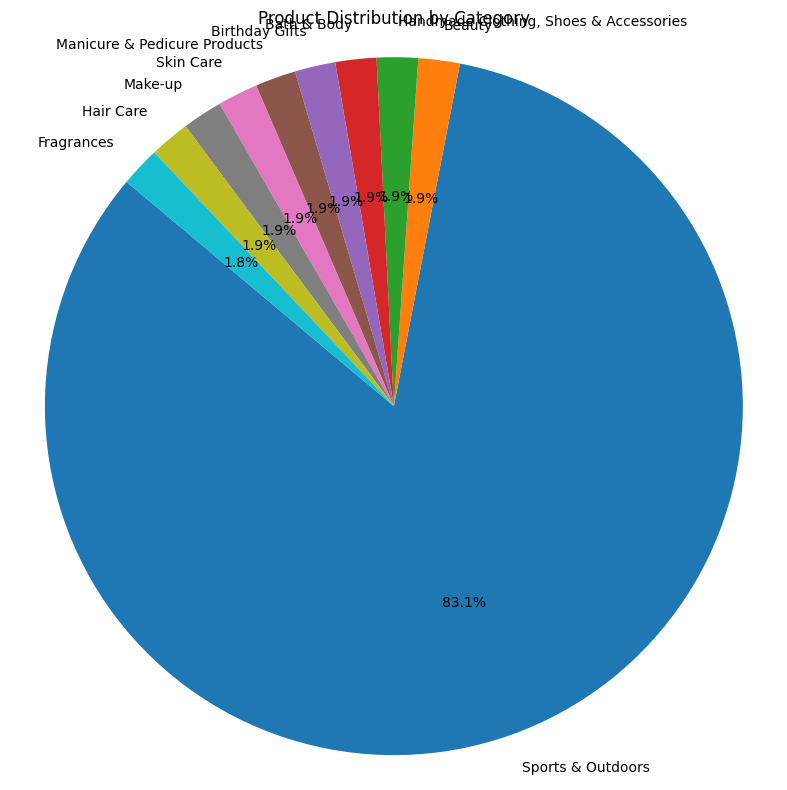

In [8]:
# Get category counts
category_counts = amz['category'].value_counts()
top = category_counts[:10]

# Plot
plt.figure(figsize=(8, 8))
plt.pie(top, labels=top.index, autopct='%1.1f%%', startangle=140)

plt.title('Product Distribution by Category')
plt.axis('equal')  # Equal aspect ratio ensures the pie is drawn as a circle
plt.tight_layout()
plt.show()

Sports & Outdoors clearly dominate the categories. 

Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [9]:
amz.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [ ]:
#Measures of centrality
f'The mean is {amz["price"].mean()}, the median is {amz["price"].median()}, the mode is {amz["price"].mode()}.'


'The mean is 89.24380943923663, the median is 19.09, the mode is 0    9.99\nName: price, dtype: float64.'

The average price point is £89 and the mode, which is the most common value is £9.99. There must be some very expensive items that are pulling the average up.

In [16]:
#Measures of dispersion
amz_price = amz['price']

stats = {
    'Variance': amz_price.var(),
    'Standard Deviation': amz_price.std(),
    'Range': amz_price.max() - amz_price.min(),
    'IQR': amz_price.quantile(0.75) - amz_price.quantile(0.25)
}

print(stats)

{'Variance': 119445.48532254907, 'Standard Deviation': 345.60886175349884, 'Range': 100000.0, 'IQR': 36.0}


There are some outliers. for the middle 50% the range is only £36 but for the whole set, the range is 100000£.

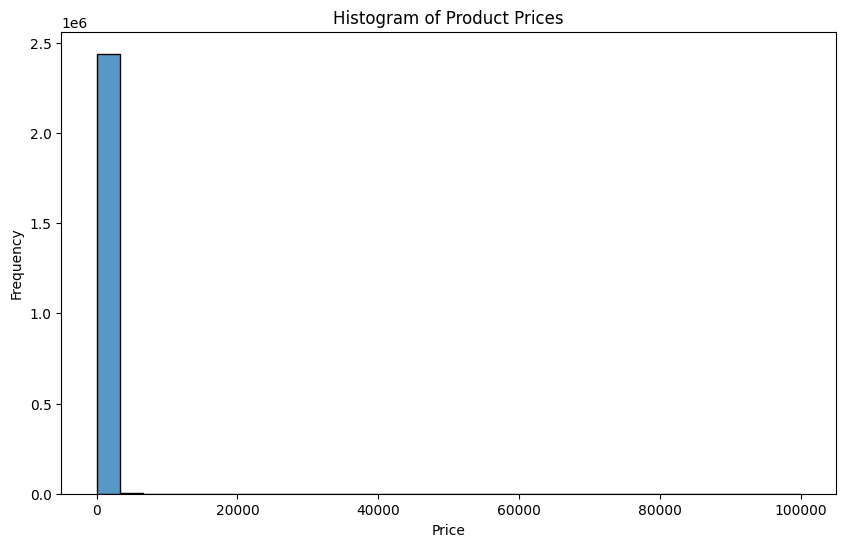

In [17]:
#Visualisations

plt.figure(figsize=(10,6))
sns.histplot(amz['price'], bins=30, kde=False)

plt.title('Histogram of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

It is a bit difficult to see the distributions. We could remove outliers and make smaller bin sizes. 

In [29]:
price_subset = amz['price'][amz['price']<500]
price_subset

0          21.99
1          23.99
2          21.99
3          31.99
4          17.99
           ...  
2443646    22.34
2443647    97.99
2443648    52.99
2443649    79.99
2443650    53.99
Name: price, Length: 2356100, dtype: float64

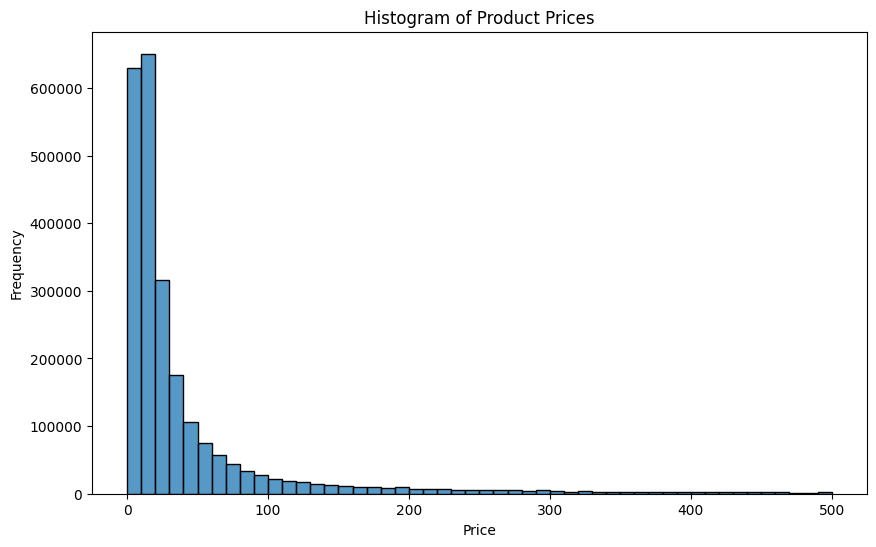

In [30]:
plt.figure(figsize=(10,6))
sns.histplot(price_subset, bins=50, kde=False)

plt.title('Histogram of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

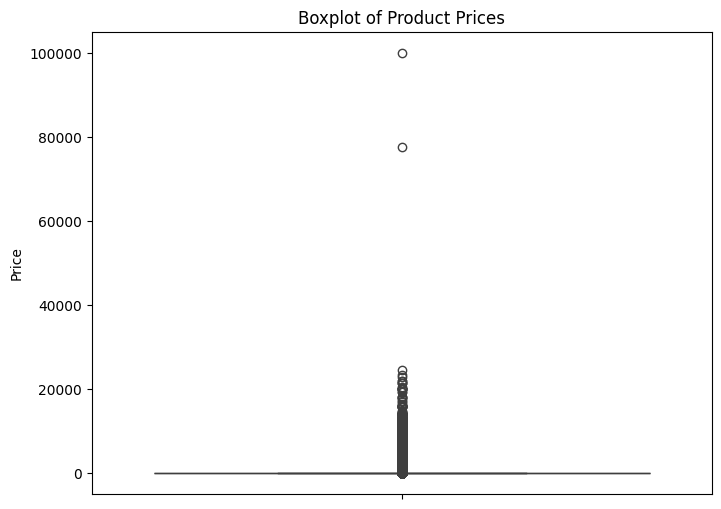

In [31]:
plt.figure(figsize=(8, 6))
sns.boxplot(y=amz['price'])
plt.title('Boxplot of Product Prices')
plt.ylabel('Price')
plt.show()

Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

In [ ]:
#Measures of Centrality
f'The mean is {amz["stars"].mean()}, the median is {amz["stars"].median()}, the mode is {amz["stars"].mode()}.'
#customers either don't rate the products or give ratings of 0.

'The mean is 2.152836472966065, the median is 0.0, the mode is 0    0.0\nName: stars, dtype: float64.'

In [34]:
#Measures of dispersion
amz_ratings = amz['stars']

stats = {
    'Variance': amz_ratings.var(),
    'Standard Deviation': amz_ratings.std(),
    'Range': amz_ratings.max() - amz_ratings.min(),
    'IQR': amz_ratings.quantile(0.75) - amz_ratings.quantile(0.25)
}

print(stats)

{'Variance': 4.817434029796862, 'Standard Deviation': 2.1948653785134207, 'Range': 5.0, 'IQR': 4.4}


In [35]:
#Shape of the distribution
skewness = amz['stars'].skew()
kurtosis = amz['stars'].kurt()

print(f"Skewness: {skewness}")
print(f"Kurtosis: {kurtosis}")

Skewness: 0.08120735761080985
Kurtosis: -1.9260061280432985


Not super skewed but skewed a little bit towards the right. Kurtosis negative means we have light tails with few outliers. 

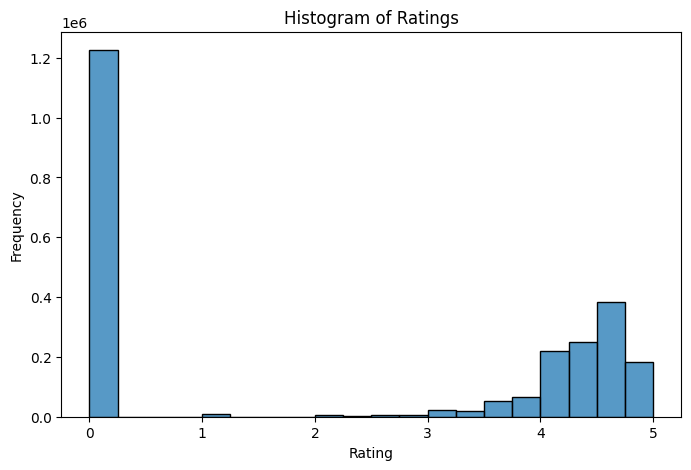

In [36]:
plt.figure(figsize=(8, 5))
sns.histplot(amz['stars'], bins=20, kde=False)

plt.title('Histogram of Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

In [ ]:
#Ratings are normally distributed if we don't account for null values. Skewed a little bit towards lower ratings. 